In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import norm

In [ ]:
df = pd.read_csv("daily_temperature_patterns.csv")

In [ ]:
df

,Date,Temperature,Feels_Like_Temperature,Humidity,Rainfall_mm,Wind_Speed_kmph,Pressure_hPa,Cloud_Cover_Percent,Sunshine_Hours,Temperature_Change,Season,Day_Type,Year
0,2025-01-01,21.0,21.8,81.2,0.0,8.4,1014.2,53.5,8.2,NaN,Winter,Weekday,2025
1,2025-01-02,18.0,18.9,65.0,0.0,11.5,1017.2,81.3,4.3,-3.0,Winter,Weekday,2025
2,2025-01-03,21.9,20.8,62.2,4.2,14.1,1010.6,72.6,5.2,3.9,Winter,Weekday,2025
3,2025-01-04,22.3,21.7,70.2,0.0,8.5,1011.7,58.6,8.7,0.4,Winter,Weekend,2025
4,2025-01-05,15.9,15.0,78.9,0.0,12.8,1013.3,93.0,2.7,-6.4,Winter,Weekend,2025
...,...,...,...,...,...,...,...,...,...,...,...,...,...
360,2025-12-27,20.2,20.9,81.4,0.0,10.7,1015.0,80.2,3.9,-0.1,Winter,Weekend,2025
361,2025-12-28,21.3,21.9,71.4,0.0,11.5,1016.1,67.7,4.3,1.1,Winter,Weekend,2025
362,2025-12-29,22.6,23.7,74.5,0.0,3.7,1015.7,65.1,5.3,1.3,Winter,Weekday,2025
363,2025-12-30,18.1,19.0,61.8,0.0,11.6,1009.4,64.0,4.9,-4.6,Winter,Weekday,2025


In [ ]:
df.head()

,Date,Temperature,Feels_Like_Temperature,Humidity,Rainfall_mm,Wind_Speed_kmph,Pressure_hPa,Cloud_Cover_Percent,Sunshine_Hours,Temperature_Change,Season,Day_Type,Year
0,2025-01-01,21.0,21.8,81.2,0.0,8.4,1014.2,53.5,8.2,NaN,Winter,Weekday,2025
1,2025-01-02,18.0,18.9,65.0,0.0,11.5,1017.2,81.3,4.3,-3.0,Winter,Weekday,2025
2,2025-01-03,21.9,20.8,62.2,4.2,14.1,1010.6,72.6,5.2,3.9,Winter,Weekday,2025
3,2025-01-04,22.3,21.7,70.2,0.0,8.5,1011.7,58.6,8.7,0.4,Winter,Weekend,2025
4,2025-01-05,15.9,15.0,78.9,0.0,12.8,1013.3,93.0,2.7,-6.4,Winter,Weekend,2025


In [ ]:
df.shape

(365, 13)

In [ ]:
df.isnull().sum()

,0
Date,0
Temperature,0
Feels_Like_Temperature,0
Humidity,0
Rainfall_mm,0
Wind_Speed_kmph,0
Pressure_hPa,0
Cloud_Cover_Percent,0
Sunshine_Hours,0
Temperature_Change,1


In [ ]:

# Convert the required columns to the correct data types
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

numeric_columns = [
    'Temperature',
    'Feels_Like_Temperature',
    'Humidity',
    'Rainfall_mm',
    'Wind_Speed_kmph',
    'Pressure_hPa',
    'Cloud_Cover_Percent',
    'Sunshine_Hours',
    'Temperature_Change'
]

df[numeric_columns] = df[numeric_columns].apply(
    pd.to_numeric, errors='coerce'
)

# Remove rows with missing Date or Temperature
df = df.dropna(subset=['Date', 'Temperature']).reset_index(drop=True)

# Define temperature for all your later analysis
temperature = df['Temperature']


In [ ]:
print("\nDESCRIPTIVE STATISTICS")

print(temperature.describe())

population_mean = temperature.mean()
population_median = temperature.median()
population_variance = temperature.var()
population_std = temperature.std()
population_skewness = temperature.skew()

print("\nPopulation Mean:", population_mean)
print("Population Median:", population_median)
print("Population Variance:", population_variance)
print("Population Standard Deviation:", population_std)
print("Population Skewness:", population_skewness)


DESCRIPTIVE STATISTICS
count    365.000000
mean      26.984384
std        5.324673
min       15.900000
25%       22.400000
50%       26.800000
75%       31.200000
max       38.900000
Name: Temperature, dtype: float64

Population Mean: 26.984383561643835
Population Median: 26.8
Population Variance: 28.352145566761983
Population Standard Deviation: 5.324673282630774
Population Skewness: 0.10095532661426777


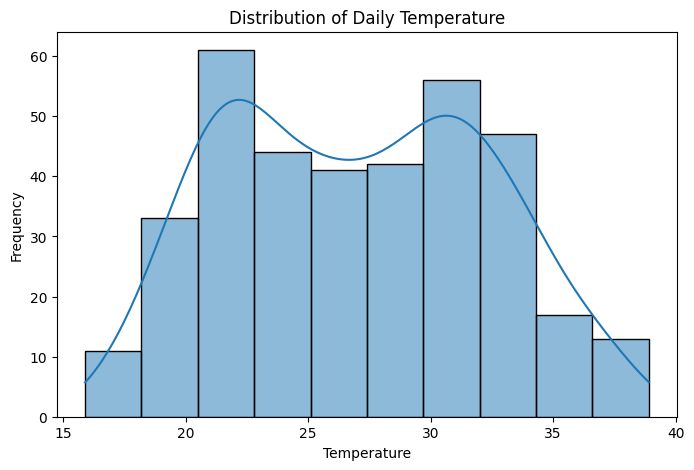

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    temperature,
    kde=True
)

plt.title("Distribution of Daily Temperature")
plt.xlabel("Temperature")
plt.ylabel("Frequency")

plt.show()


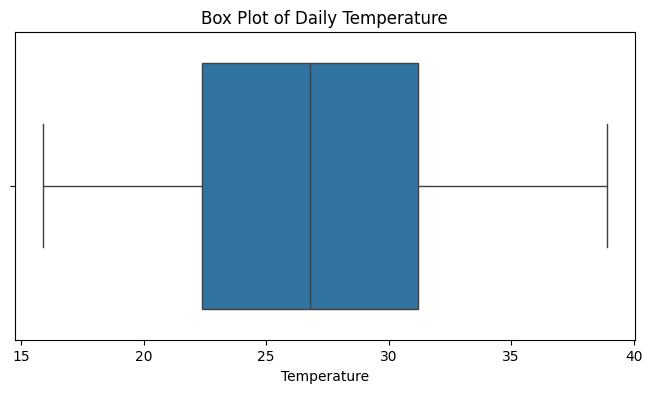

In [ ]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    x=temperature
)

plt.title("Box Plot of Daily Temperature")
plt.xlabel("Temperature")

plt.show()


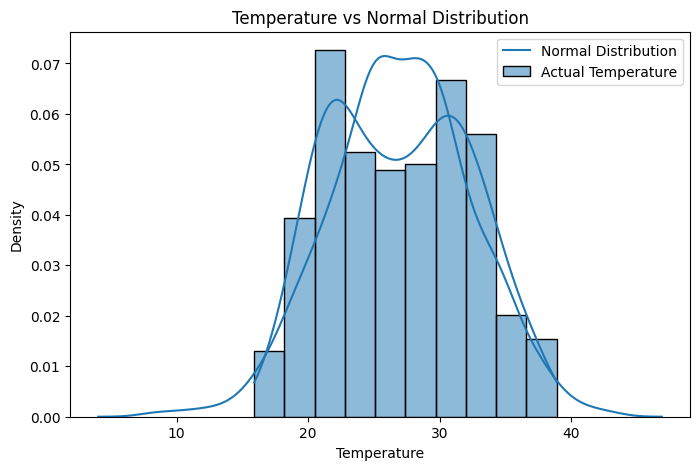

In [ ]:
normal_data = np.random.normal(
    population_mean,
    population_std,
    2000
)

plt.figure(figsize=(8, 5))

sns.histplot(
    temperature,
    kde=True,
    stat="density",
    label="Actual Temperature"
)

sns.kdeplot(
    normal_data,
    label="Normal Distribution"
)

plt.title("Temperature vs Normal Distribution")
plt.xlabel("Temperature")
plt.ylabel("Density")
plt.legend()

plt.show()

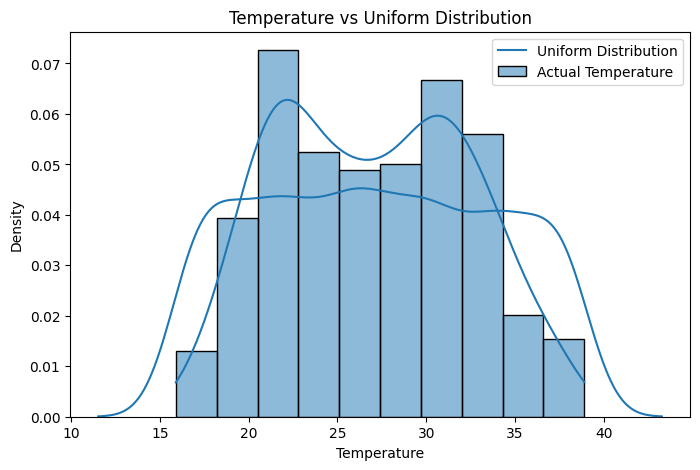

In [ ]:
uniform_data = np.random.uniform(
    temperature.min(),
    temperature.max(),
    2000
)

plt.figure(figsize=(8, 5))

sns.histplot(
    temperature,
    kde=True,
    stat="density",
    label="Actual Temperature"
)

sns.kdeplot(
    uniform_data,
    label="Uniform Distribution"
)

plt.title("Temperature vs Uniform Distribution")
plt.xlabel("Temperature")
plt.ylabel("Density")
plt.legend()

plt.show()

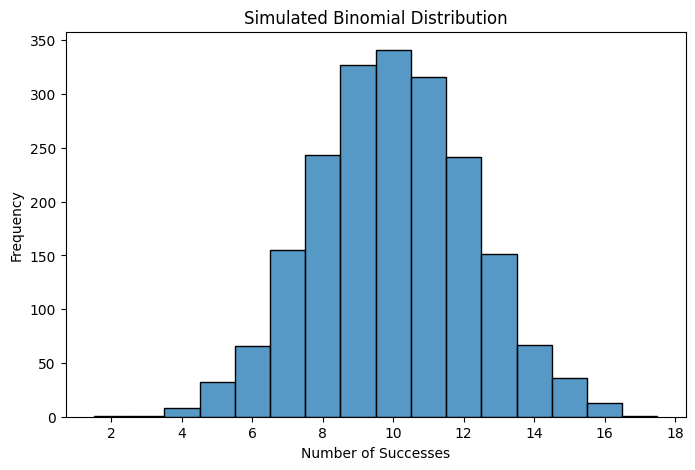

In [ ]:
binomial_data = np.random.binomial(
    n=20,
    p=0.5,
    size=2000
)

plt.figure(figsize=(8, 5))

sns.histplot(
    binomial_data,
    discrete=True
)

plt.title("Simulated Binomial Distribution")
plt.xlabel("Number of Successes")
plt.ylabel("Frequency")

plt.show()

In [ ]:
print("\nSkewness:", population_skewness)

if abs(population_skewness) < 0.5:
    print("Temperature distribution is approximately symmetric.")
elif population_skewness > 0:
    print("Temperature distribution is positively skewed.")
else:
    print("Temperature distribution is negatively skewed.")


Skewness: 0.10095532661426777
Temperature distribution is approximately symmetric.


In [ ]:
simple_sample = df.sample(
    n=30,
    random_state=42
)

print("\nSIMPLE RANDOM SAMPLING")

print("Mean:",
      simple_sample['Temperature'].mean())

print("Variance:",
      simple_sample['Temperature'].var())

print("Standard Deviation:",
      simple_sample['Temperature'].std())


SIMPLE RANDOM SAMPLING
Mean: 26.893333333333334
Variance: 33.151678160919545
Standard Deviation: 5.75774940067033


In [ ]:
step = max(1, len(df) // 30)

start = np.random.randint(0, step)

systematic_sample = df.iloc[
    start::step
].head(30)

print("\nSYSTEMATIC SAMPLING")

print("Mean:",
      systematic_sample['Temperature'].mean())

print("Variance:",
      systematic_sample['Temperature'].var())

print("Standard Deviation:",
      systematic_sample['Temperature'].std())


SYSTEMATIC SAMPLING
Mean: 27.063333333333333
Variance: 36.08929885057471
Standard Deviation: 6.007436961847765


In [ ]:
def get_season(month):

    if month in [12, 1, 2]:
        return "Winter"

    elif month in [3, 4, 5]:
        return "Summer"

    elif month in [6, 7, 8, 9]:
        return "Monsoon"

    else:
        return "Post-Monsoon"


df['Season_Calculated'] = df['Date'].dt.month.apply(
    get_season
)

# Take proportional samples from each season
stratified_parts = []

total_sample_size = 30

for season_name, group in df.groupby('Season_Calculated'):

    proportion = len(group) / len(df)

    sample_n = max(
        1,
        round(proportion * total_sample_size)
    )

    sample_n = min(
        sample_n,
        len(group)
    )

    part = group.sample(
        n=sample_n,
        random_state=42
    )

    stratified_parts.append(part)

stratified_sample = pd.concat(
    stratified_parts
)

# Adjust to exactly 30 if necessary
if len(stratified_sample) > 30:
    stratified_sample = stratified_sample.sample(
        n=30,
        random_state=42
    )

print("\nSTRATIFIED SAMPLING")

print("Mean:",
      stratified_sample['Temperature'].mean())

print("Variance:",
      stratified_sample['Temperature'].var())

print("Standard Deviation:",
      stratified_sample['Temperature'].std())


STRATIFIED SAMPLING
Mean: 27.483333333333334
Variance: 29.344885057471256
Standard Deviation: 5.417091937328667


In [ ]:
df['Month_Calculated'] = df['Date'].dt.month

available_months = df['Month_Calculated'].unique()

selected_months = np.random.choice(
    available_months,
    size=3,
    replace=False
)

cluster_sample = df[
    df['Month_Calculated'].isin(selected_months)
]

print("\nCLUSTER SAMPLING")

print("Selected Months:",
      selected_months)

print("Number of Records:",
      len(cluster_sample))

print("Mean:",
      cluster_sample['Temperature'].mean())

print("Variance:",
      cluster_sample['Temperature'].var())

print("Standard Deviation:",
      cluster_sample['Temperature'].std())


CLUSTER SAMPLING
Selected Months: [6 2 4]
Number of Records: 88
Mean: 26.56931818181818
Variance: 27.921691483803546
Standard Deviation: 5.284097982040411


In [ ]:
sampling_results = pd.DataFrame({

    'Sampling Method': [
        'Simple Random',
        'Systematic',
        'Stratified',
        'Cluster'
    ],

    'Mean Temperature': [
        simple_sample['Temperature'].mean(),
        systematic_sample['Temperature'].mean(),
        stratified_sample['Temperature'].mean(),
        cluster_sample['Temperature'].mean()
    ],

    'Variance': [
        simple_sample['Temperature'].var(),
        systematic_sample['Temperature'].var(),
        stratified_sample['Temperature'].var(),
        cluster_sample['Temperature'].var()
    ],

    'Standard Deviation': [
        simple_sample['Temperature'].std(),
        systematic_sample['Temperature'].std(),
        stratified_sample['Temperature'].std(),
        cluster_sample['Temperature'].std()
    ]
})

print("\nSAMPLING METHODS COMPARISON")
print(sampling_results)


SAMPLING METHODS COMPARISON
  Sampling Method  Mean Temperature   Variance  Standard Deviation
0   Simple Random         26.893333  33.151678            5.757749
1      Systematic         27.063333  36.089299            6.007437
2      Stratified         27.483333  29.344885            5.417092
3         Cluster         26.569318  27.921691            5.284098


In [ ]:
comparison_results = []

for n in [30, 50, 100]:

    sample = temperature.sample(
        n=n,
        random_state=42
    )

    sample_mean = sample.mean()
    sample_median = sample.median()
    sample_variance = sample.var()
    sample_std = sample.std()

    comparison_results.append({

        'Sample Size': n,

        'Sample Mean': sample_mean,

        'Sample Median': sample_median,

        'Sample Variance': sample_variance,

        'Sample SD': sample_std
    })

comparison_table = pd.DataFrame(
    comparison_results
)

print("\nSAMPLE STATISTICS")
print(comparison_table)



SAMPLE STATISTICS
   Sample Size  Sample Mean  Sample Median  Sample Variance  Sample SD
0           30    26.893333          27.85        33.151678   5.757749
1           50    25.688000          24.85        30.655363   5.536729
2          100    26.160000          24.85        30.965455   5.564661


In [ ]:
population_sample_table = pd.DataFrame({

    'Statistic': [
        'Mean',
        'Median',
        'Variance',
        'Standard Deviation'
    ],

    'Population': [
        population_mean,
        population_median,
        population_variance,
        population_std
    ],

    'Sample 30': [
        temperature.sample(30, random_state=42).mean(),
        temperature.sample(30, random_state=42).median(),
        temperature.sample(30, random_state=42).var(),
        temperature.sample(30, random_state=42).std()
    ],

    'Sample 50': [
        temperature.sample(50, random_state=42).mean(),
        temperature.sample(50, random_state=42).median(),
        temperature.sample(50, random_state=42).var(),
        temperature.sample(50, random_state=42).std()
    ],

    'Sample 100': [
        temperature.sample(100, random_state=42).mean(),
        temperature.sample(100, random_state=42).median(),
        temperature.sample(100, random_state=42).var(),
        temperature.sample(100, random_state=42).std()
    ]
})

print("\nPOPULATION VS SAMPLE")
print(population_sample_table)


POPULATION VS SAMPLE
            Statistic  Population  Sample 30  Sample 50  Sample 100
0                Mean   26.984384  26.893333  25.688000   26.160000
1              Median   26.800000  27.850000  24.850000   24.850000
2            Variance   28.352146  33.151678  30.655363   30.965455
3  Standard Deviation    5.324673   5.757749   5.536729    5.564661





CENTRAL LIMIT THEOREM


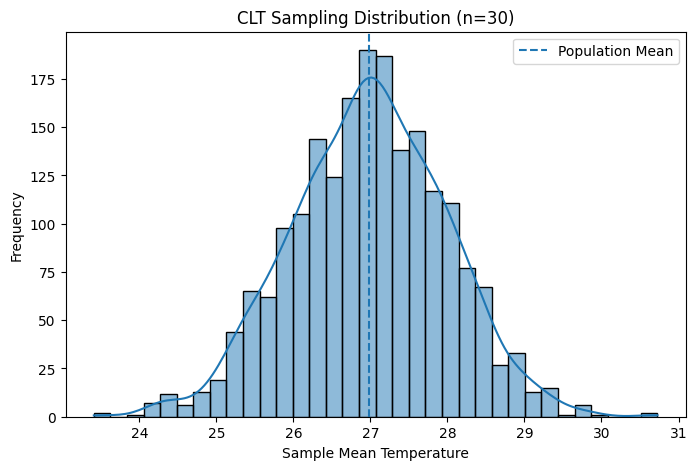

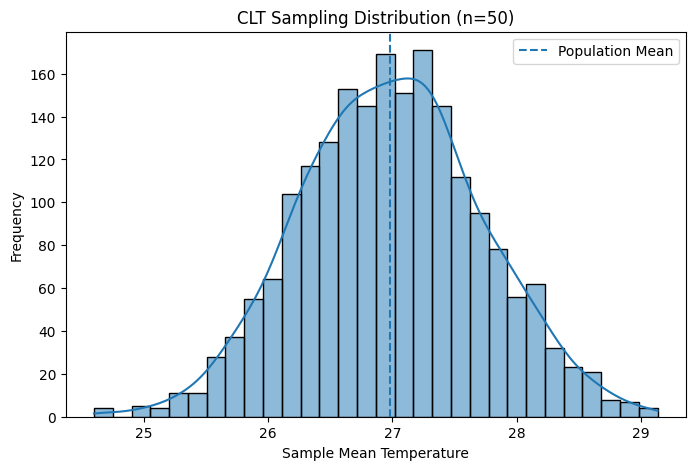

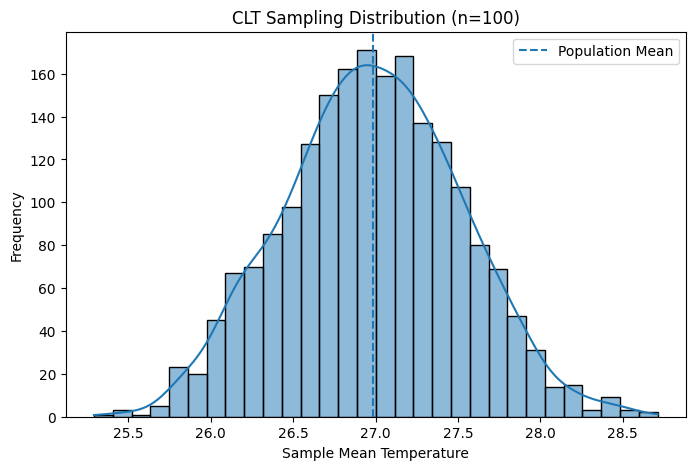

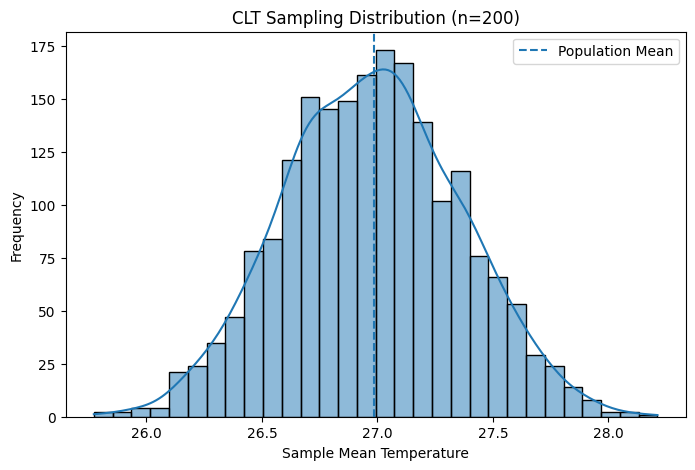


CLT RESULTS
   Sample Size  Mean of Sample Means  Theoretical SE  Observed SE
0           30             26.983075        0.972148     1.002144
1           50             26.990158        0.753023     0.733995
2          100             26.982300        0.532467     0.534278
3          200             26.976560        0.376511     0.379398


In [ ]:
print("\n\n")
print("=" * 60)
print("CENTRAL LIMIT THEOREM")
print("=" * 60)


clt_results = []

for n in [30, 50, 100, 200]:

    means = []

    for i in range(2000):

        sample = np.random.choice(
            temperature,
            size=n,
            replace=True
        )

        means.append(
            sample.mean()
        )

    means = np.array(means)

    theoretical_se = (
        population_std / np.sqrt(n)
    )

    observed_se = means.std(ddof=1)

    clt_results.append({

        'Sample Size': n,

        'Mean of Sample Means':
            means.mean(),

        'Theoretical SE':
            theoretical_se,

        'Observed SE':
            observed_se
    })

    # Separate plot for every sample size
    plt.figure(figsize=(8, 5))

    sns.histplot(
        means,
        kde=True
    )

    plt.axvline(
        population_mean,
        linestyle='--',
        label='Population Mean'
    )

    plt.title(
        f"CLT Sampling Distribution (n={n})"
    )

    plt.xlabel("Sample Mean Temperature")
    plt.ylabel("Frequency")

    plt.legend()

    plt.show()

    clt_table = pd.DataFrame(
    clt_results
)

print("\nCLT RESULTS")
print(clt_table)


In [ ]:
for n in [10, 30, 50, 100, 200]:

    se = population_std / np.sqrt(n)

    print(
        "Sample Size:",
        n,
        "| Standard Error:",
        se
    )


Sample Size: 10 | Standard Error: 1.6838095369358725
Sample Size: 30 | Standard Error: 0.9721478894139852
Sample Size: 50 | Standard Error: 0.7530225171502108
Sample Size: 100 | Standard Error: 0.5324673282630774
Sample Size: 200 | Standard Error: 0.3765112585751054


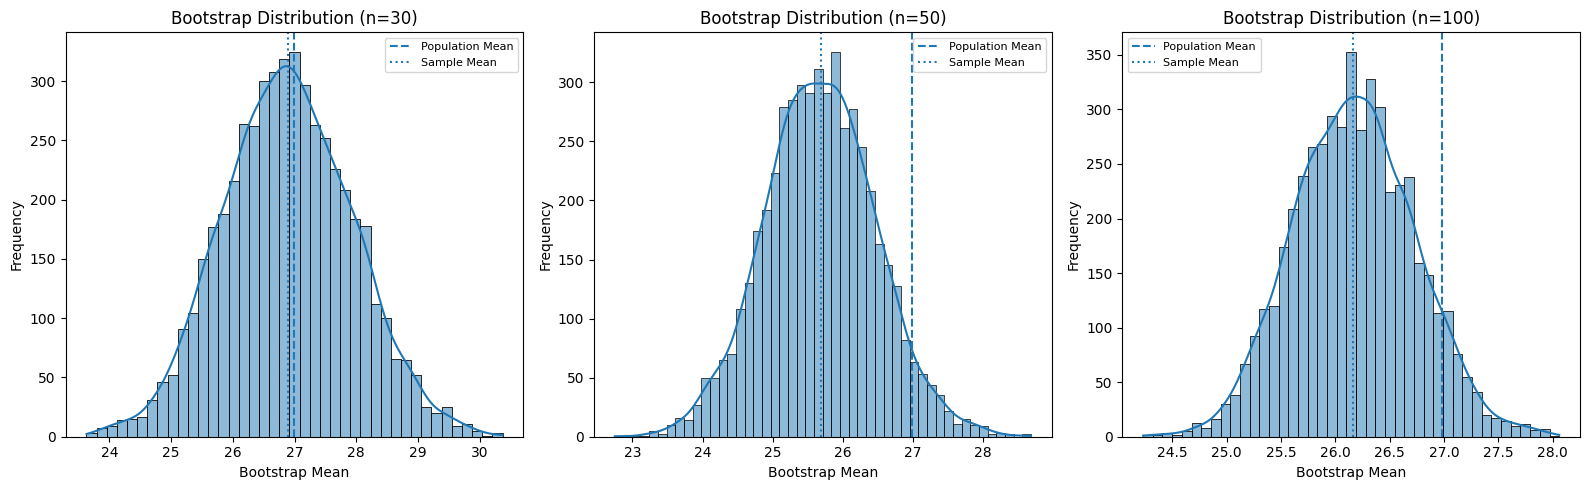

In [ ]:

bootstrap_means = {}

for n in [30, 50, 100]:
    sample = df['Temperature'].dropna().sample(
        n=n, random_state=42
    ).to_numpy()

    means = []
    for i in range(5000):
        bootstrap_sample = np.random.choice(
            sample, size=n, replace=True
        )
        means.append(bootstrap_sample.mean())

    bootstrap_means[n] = np.array(means)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, n in zip(axes, [30, 50, 100]):
    sns.histplot(bootstrap_means[n], kde=True, ax=ax)

    ax.axvline(
        df['Temperature'].mean(),
        linestyle='--',
        label='Population Mean'
    )
    ax.axvline(
        df['Temperature'].dropna().sample(
            n=n, random_state=42
        ).mean(),
        linestyle=':',
        label='Sample Mean'
    )

    ax.set_title(f'Bootstrap Distribution (n={n})')
    ax.set_xlabel('Bootstrap Mean')
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


In [ ]:
bootstrap_results = []

for n in [30, 50, 100]:

    sample = temperature.sample(
        n=n,
        random_state=42
    )

    bootstrap_values = []

    for i in range(5000):

        b_sample = np.random.choice(
            sample,
            size=n,
            replace=True
        )

        bootstrap_values.append(
            b_sample.mean()
        )

    bootstrap_results.append({

        'Sample Size': n,

        'Sample Mean': sample.mean(),

        'Bootstrap Mean':
            np.mean(bootstrap_values),

        'Population Mean':
            population_mean
    })

bootstrap_table = pd.DataFrame(
    bootstrap_results
)

print("\nBOOTSTRAP RESULTS")
print(bootstrap_table)



BOOTSTRAP RESULTS
   Sample Size  Sample Mean  Bootstrap Mean  Population Mean
0           30    26.893333       26.906921        26.984384
1           50    25.688000       25.686166        26.984384
2          100    26.160000       26.150535        26.984384


In [ ]:
sample_means = []
sample_medians = []

for i in range(1000):

    sample = np.random.choice(
        temperature,
        size=30,
        replace=True
    )

    sample_means.append(
        sample.mean()
    )

    sample_medians.append(
        np.median(sample)
    )


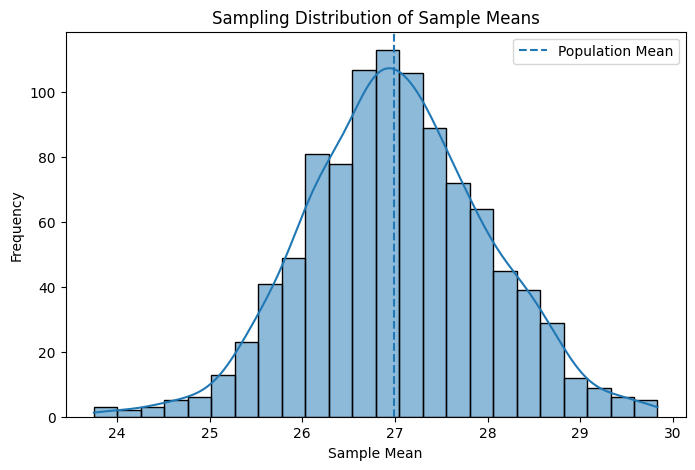

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    sample_means,
    kde=True
)

plt.axvline(
    population_mean,
    linestyle='--',
    label='Population Mean'
)

plt.title(
    "Sampling Distribution of Sample Means"
)

plt.xlabel("Sample Mean")
plt.ylabel("Frequency")

plt.legend()

plt.show()

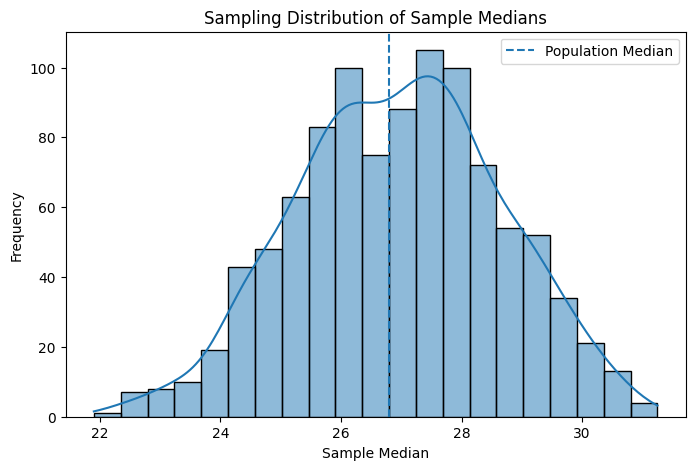

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    sample_medians,
    kde=True
)

plt.axvline(
    population_median,
    linestyle='--',
    label='Population Median'
)

plt.title(
    "Sampling Distribution of Sample Medians"
)

plt.xlabel("Sample Median")
plt.ylabel("Frequency")

plt.legend()

plt.show()


In [ ]:
mean_estimator_variance = np.var(
    sample_means,
    ddof=1
)

median_estimator_variance = np.var(
    sample_medians,
    ddof=1
)

print("\nVariance of Mean Estimator:",
      mean_estimator_variance)

print("Variance of Median Estimator:",
      median_estimator_variance)
estimator_results = []

for n in [30, 50, 100]:

    means = []
    medians = []

    for i in range(1000):

        sample = np.random.choice(
            temperature,
            size=n,
            replace=True
        )

        means.append(
            sample.mean()
        )

        medians.append(
            np.median(sample)
        )

    estimator_results.append({

        'Sample Size': n,

        'Mean Estimator Variance':
            np.var(means, ddof=1),

        'Median Estimator Variance':
            np.var(medians, ddof=1),

        'Mean Estimator Average':
            np.mean(means),

        'Median Estimator Average':
            np.mean(medians)
    })

estimator_table = pd.DataFrame(
    estimator_results
)

print("\nMEAN VS MEDIAN RESULTS")
print(estimator_table)


Variance of Mean Estimator: 0.9436014813813818
Variance of Median Estimator: 2.86713988988989

MEAN VS MEDIAN RESULTS
   Sample Size  Mean Estimator Variance  Median Estimator Variance  \
0           30                 0.941522                   2.941576   
1           50                 0.566010                   1.925653   
2          100                 0.274527                   0.930374   

   Mean Estimator Average  Median Estimator Average  
0               26.983800                  26.91155  
1               26.962094                  26.84995  
2               26.990525                  26.91155  


In [ ]:
confidence_results = []

for n in [10, 30, 50, 100]:

    sample = temperature.sample(
        n=n,
        random_state=42
    )

    sample_mean = sample.mean()

    sample_se = (
        sample.std(ddof=1)
        / np.sqrt(n)
    )

    z_value = norm.ppf(0.975)

    margin = z_value * sample_se

    lower = sample_mean - margin
    upper = sample_mean + margin

    confidence_results.append({

        'Sample Size': n,

        'Sample Mean': sample_mean,

        'Standard Error': sample_se,

        'Lower CI': lower,

        'Upper CI': upper
    })

confidence_table = pd.DataFrame(
    confidence_results
)

print(confidence_table)

   Sample Size  Sample Mean  Standard Error   Lower CI   Upper CI
0           10    27.360000        2.095933  23.252048  31.467952
1           30    26.893333        1.051216  24.832987  28.953680
2           50    25.688000        0.783012  24.153325  27.222675
3          100    26.160000        0.556466  25.069346  27.250654


In [ ]:
coverage_results = []

for n in [10, 30, 50, 100]:

    covered = 0

    for i in range(1000):

        sample = np.random.choice(
            temperature,
            size=n,
            replace=True
        )

        sample_mean = sample.mean()

        sample_se = (
            sample.std(ddof=1)
            / np.sqrt(n)
        )

        margin = (
            norm.ppf(0.975)
            * sample_se
        )

        lower = sample_mean - margin
        upper = sample_mean + margin

        if (
            lower <= population_mean
            and population_mean <= upper
        ):
            covered += 1

    coverage = covered / 1000

    coverage_results.append({

        'Sample Size': n,

        'Coverage Probability':
            coverage
    })

coverage_table = pd.DataFrame(
    coverage_results
)

print(coverage_table)

   Sample Size  Coverage Probability
0           10                 0.920
1           30                 0.933
2           50                 0.935
3          100                 0.953


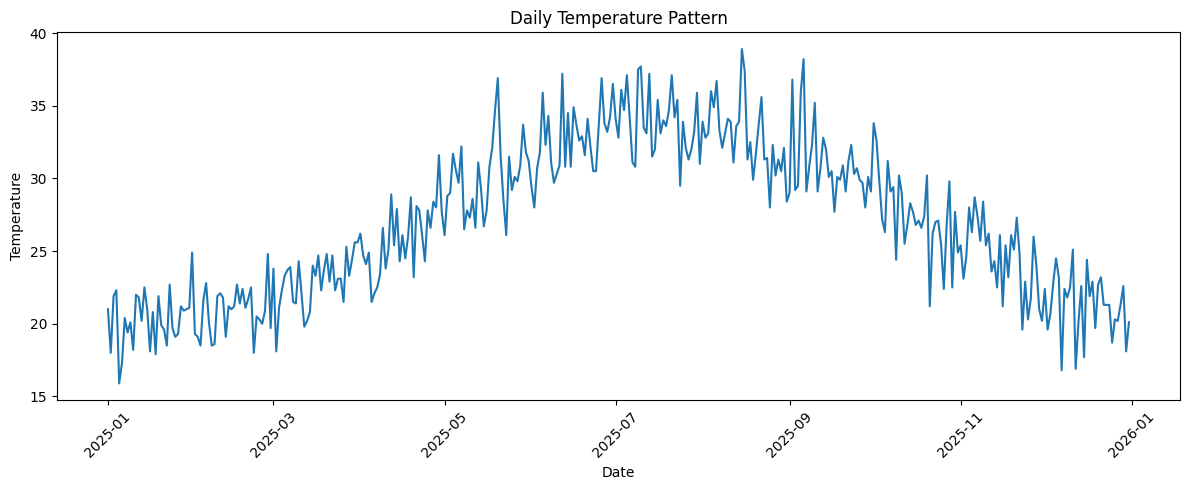

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    df['Date'],
    df['Temperature']
)

plt.title(
    "Daily Temperature Pattern"
)

plt.xlabel("Date")
plt.ylabel("Temperature")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

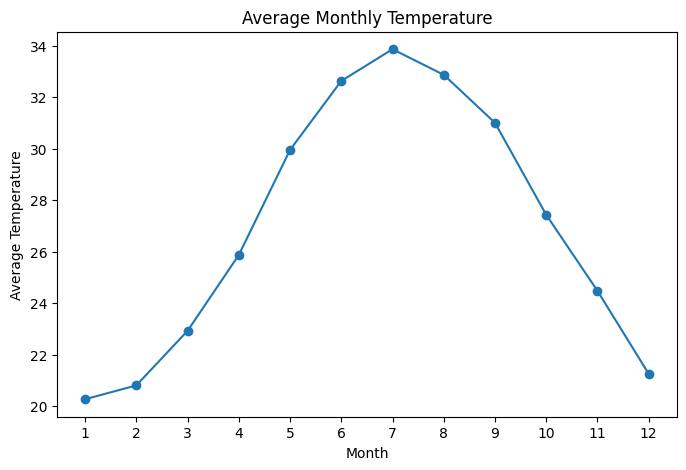

In [ ]:
df['Month_Number'] = df['Date'].dt.month

monthly_temperature = (
    df.groupby('Month_Number')['Temperature']
    .mean()
)

plt.figure(figsize=(8, 5))

plt.plot(
    monthly_temperature.index,
    monthly_temperature.values,
    marker='o'
)

plt.title(
    "Average Monthly Temperature"
)

plt.xlabel("Month")
plt.ylabel("Average Temperature")

plt.xticks(range(1, 13))

plt.show()

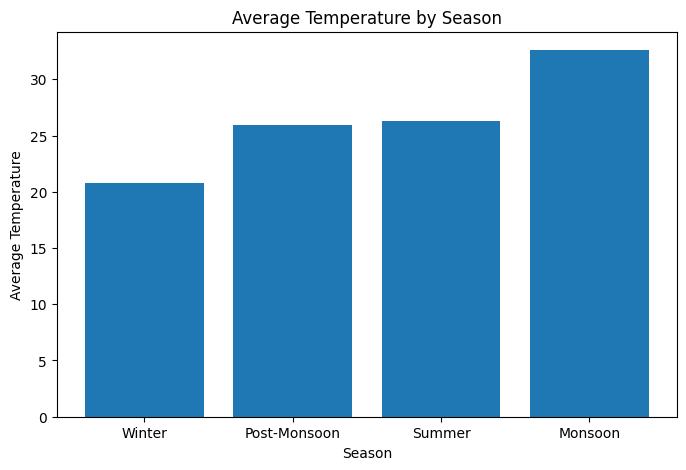

In [ ]:
seasonal_temperature = (
    df.groupby('Season_Calculated')['Temperature']
    .mean()
    .sort_values()
)

plt.figure(figsize=(8, 5))

plt.bar(
    seasonal_temperature.index,
    seasonal_temperature.values
)

plt.title(
    "Average Temperature by Season"
)

plt.xlabel("Season")
plt.ylabel("Average Temperature")

plt.show()

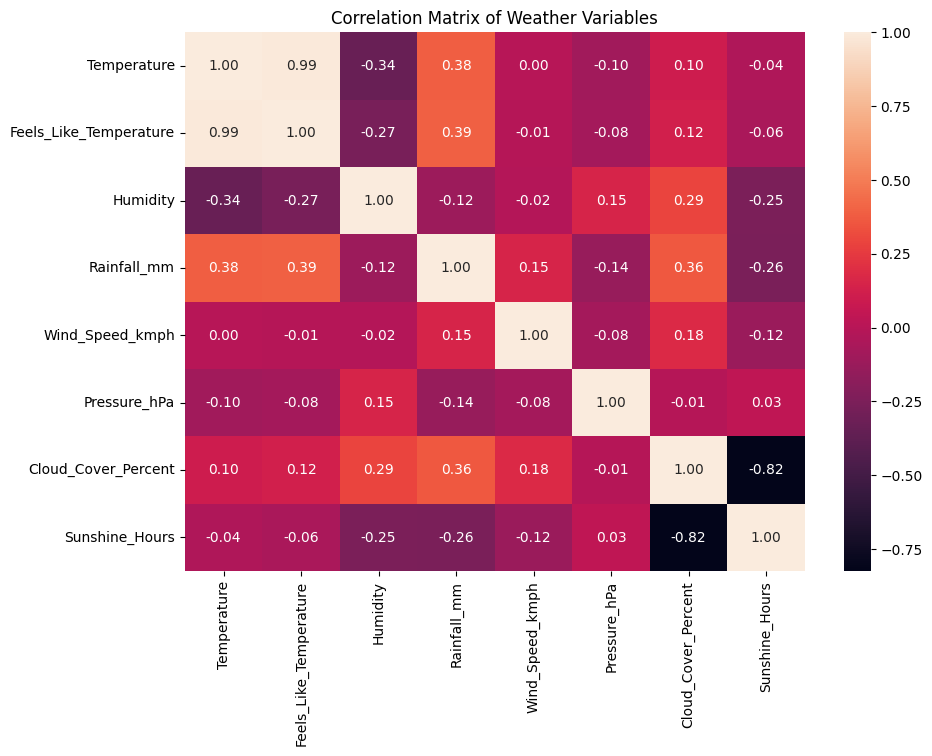

In [ ]:
weather_columns = [
    'Temperature',
    'Feels_Like_Temperature',
    'Humidity',
    'Rainfall_mm',
    'Wind_Speed_kmph',
    'Pressure_hPa',
    'Cloud_Cover_Percent',
    'Sunshine_Hours'
]

correlation = df[weather_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title(
    "Correlation Matrix of Weather Variables"
)

plt.show()


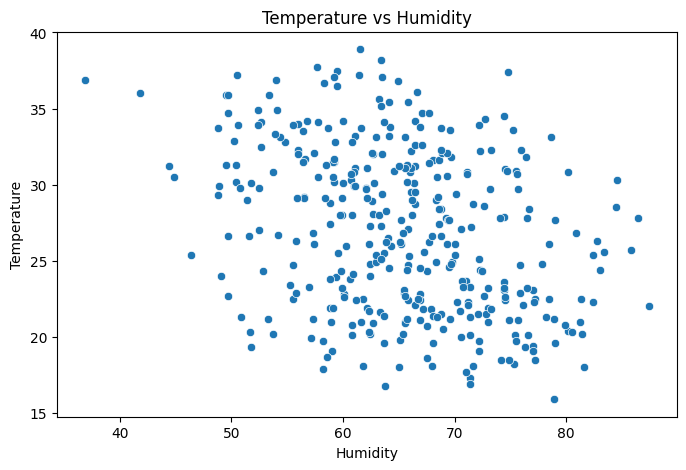

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Humidity',
    y='Temperature'
)

plt.title(
    "Temperature vs Humidity"
)

plt.xlabel("Humidity")
plt.ylabel("Temperature")

plt.show()

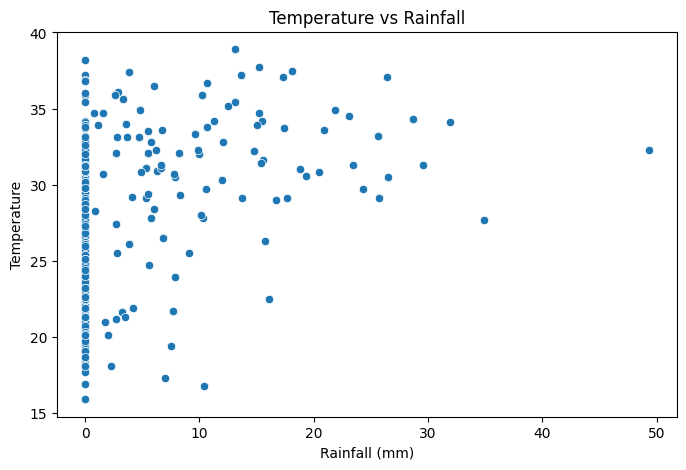

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Rainfall_mm',
    y='Temperature'
)

plt.title(
    "Temperature vs Rainfall"
)

plt.xlabel("Rainfall (mm)")
plt.ylabel("Temperature")

plt.show()

In [ ]:
#  Z-test and one-sample t-test

from scipy.stats import norm, ttest_1samp
import numpy as np

alpha = 0.05
mu0 = 27.0

x = df["Temperature"].dropna()
n = len(x)
sample_mean = x.mean()
sample_sd = x.std(ddof=1)

# One-sample t-test: population SD is unknown
t_stat, t_pvalue = ttest_1samp(x, popmean=mu0)

print("ONE-SAMPLE T-TEST")
print("Sample mean:", sample_mean)
print("t-statistic:", t_stat)
print("p-value:", t_pvalue)
print("Decision:", "Reject H0" if t_pvalue < alpha
      else "Fail to reject H0")

# Z-test demonstration:
# This assumes a genuinely known population SD.
# Here population_std is the SD of the available dataset,
# so the result is illustrative rather than a true known-SD Z-test.
sigma_known = population_std

z_stat = (sample_mean - mu0) / (sigma_known / np.sqrt(n))
z_pvalue = 2 * norm.sf(abs(z_stat))

print("\nONE-SAMPLE Z-TEST (illustrative)")
print("Z-statistic:", z_stat)
print("p-value:", z_pvalue)
print("Decision:", "Reject H0" if z_pvalue < alpha
      else "Fail to reject H0")


ONE-SAMPLE T-TEST
Sample mean: 26.984383561643835
t-statistic: -0.05603191407999973
p-value: 0.9553471261543904
Decision: Fail to reject H0

ONE-SAMPLE Z-TEST (illustrative)
Z-statistic: -0.05603191407999975
p-value: 0.9553163833296967
Decision: Fail to reject H0


In [ ]:
#  Chi-square test of independence

from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(df["Season"], df["Day_Type"])

print("Observed frequencies:")
display(contingency_table)

chi2_stat, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2_stat)
print("Degrees of freedom:", dof)
print("p-value:", p_value)
print("Decision:", "Reject H0" if p_value < 0.05
      else "Fail to reject H0")

print("\nExpected frequencies:")
display(pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
).round(2))

if (expected < 5).any():
    print("Warning: Some expected frequencies are below 5.")


Observed frequencies:


Day_Type,Weekday,Weekend
Season,,
Monsoon,87,35
Post-Monsoon,43,18
Summer,65,27
Winter,66,24


Chi-square statistic: 0.21347876791952874
Degrees of freedom: 3
p-value: 0.9753845819354227
Decision: Fail to reject H0

Expected frequencies:


Day_Type,Weekday,Weekend
Season,,
Monsoon,87.24,34.76
Post-Monsoon,43.62,17.38
Summer,65.79,26.21
Winter,64.36,25.64


Covariance Matrix:


,Temperature,Feels_Like_Temperature,Humidity,Rainfall_mm,Wind_Speed_kmph,Pressure_hPa,Cloud_Cover_Percent,Sunshine_Hours
Temperature,28.352,28.084,-15.601,13.889,0.005,-1.830,7.218,-0.363
Feels_Like_Temperature,28.084,28.548,-12.460,14.153,-0.118,-1.567,9.239,-0.559
Humidity,-15.601,-12.460,75.504,-6.988,-0.511,4.568,35.068,-3.840
Rainfall_mm,13.889,14.153,-6.988,46.005,3.862,-3.301,34.136,-3.041
Wind_Speed_kmph,0.005,-0.118,-0.511,3.862,14.426,-1.095,9.327,-0.797
Pressure_hPa,-1.830,-1.567,4.568,-3.301,-1.095,12.640,-0.481,0.206
Cloud_Cover_Percent,7.218,9.239,35.068,34.136,9.327,-0.481,196.586,-20.107
Sunshine_Hours,-0.363,-0.559,-3.840,-3.041,-0.797,0.206,-20.107,3.027



Temperature-Humidity Covariance: -15.601414195393648


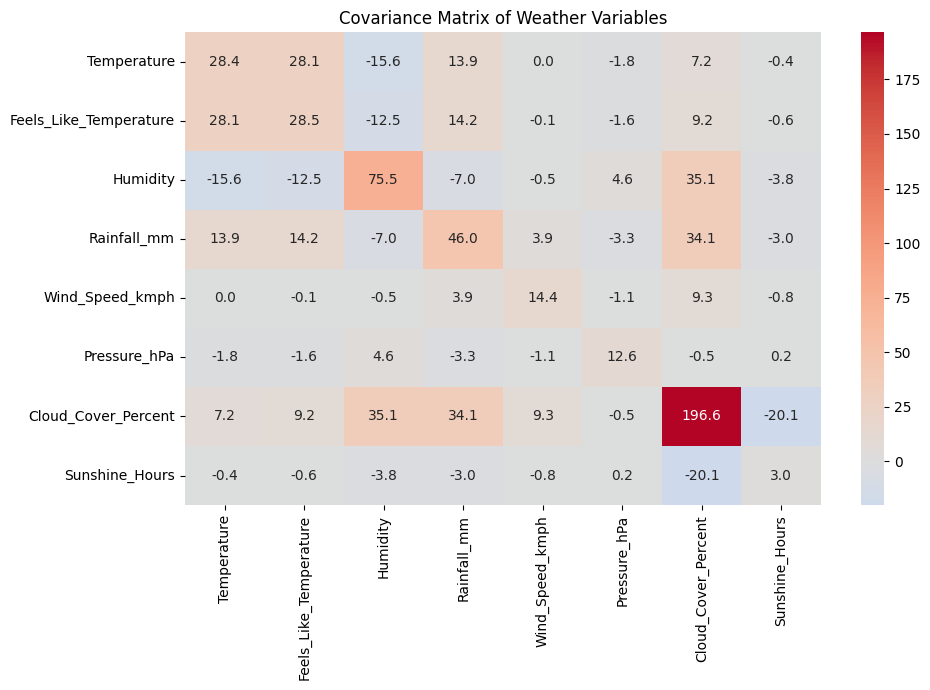

In [ ]:
# Covariance analysis

weather_columns = [
    "Temperature",
    "Feels_Like_Temperature",
    "Humidity",
    "Rainfall_mm",
    "Wind_Speed_kmph",
    "Pressure_hPa",
    "Cloud_Cover_Percent",
    "Sunshine_Hours"
]

covariance_matrix = df[weather_columns].cov()

print("Covariance Matrix:")
display(covariance_matrix.round(3))

print("\nTemperature-Humidity Covariance:",
      df["Temperature"].cov(df["Humidity"]))

plt.figure(figsize=(10, 7))
sns.heatmap(covariance_matrix, annot=True, fmt=".1f",
            cmap="coolwarm", center=0)
plt.title("Covariance Matrix of Weather Variables")
plt.tight_layout()
plt.show()


In [ ]:
#  Pearson and Spearman hypothesis testing

from scipy.stats import pearsonr, spearmanr

pairs = [
    ("Temperature", "Humidity"),
    ("Temperature", "Rainfall_mm"),
    ("Temperature", "Sunshine_Hours"),
    ("Temperature", "Wind_Speed_kmph")
]

correlation_results = []

for col1, col2 in pairs:
    pair_data = df[[col1, col2]].dropna()

    pearson_r, pearson_p = pearsonr(
        pair_data[col1], pair_data[col2]
    )
    spearman_r, spearman_p = spearmanr(
        pair_data[col1], pair_data[col2]
    )

    correlation_results.append({
        "Variable 1": col1,
        "Variable 2": col2,
        "Pearson r": pearson_r,
        "Pearson p-value": pearson_p,
        "Pearson decision": (
            "Reject H0" if pearson_p < 0.05
            else "Fail to reject H0"
        ),
        "Spearman rho": spearman_r,
        "Spearman p-value": spearman_p,
        "Spearman decision": (
            "Reject H0" if spearman_p < 0.05
            else "Fail to reject H0"
        )
    })

correlation_test_table = pd.DataFrame(correlation_results)
display(correlation_test_table.round(4))


,Variable 1,Variable 2,Pearson r,Pearson p-value,Pearson decision,Spearman rho,Spearman p-value,Spearman decision
0,Temperature,Humidity,-0.3372,0.000,Reject H0,-0.3267,0.0000,Reject H0
1,Temperature,Rainfall_mm,0.3846,0.000,Reject H0,0.4326,0.0000,Reject H0
2,Temperature,Sunshine_Hours,-0.0392,0.455,Fail to reject H0,-0.0321,0.5411,Fail to reject H0
3,Temperature,Wind_Speed_kmph,0.0003,0.996,Fail to reject H0,-0.0040,0.9398,Fail to reject H0


In [ ]:
#  Two-way ANOVA

import statsmodels.api as sm
from statsmodels.formula.api import ols

anova_data = df[
    ["Temperature", "Season_Calculated", "Day_Type"]
].dropna().copy()

anova_model = ols(
    "Temperature ~ C(Season_Calculated) * C(Day_Type)",
    data=anova_data
).fit()

anova_table = sm.stats.anova_lm(anova_model, typ=2)

print("TWO-WAY ANOVA RESULTS")
display(anova_table)

for effect in anova_table.index:
    p = anova_table.loc[effect, "PR(>F)"]
    print(
        effect,
        "| p-value:", round(p, 5),
        "|", "Significant" if p < 0.05
        else "Not statistically significant"
    )

# Residual normality diagnostic
shapiro_stat, shapiro_p = stats.shapiro(anova_model.resid)
print("\nShapiro-Wilk residual normality test p-value:",
      shapiro_p)

# Equal-variance diagnostic across season/day-type groups
groups = [
    group["Temperature"].values
    for _, group in anova_data.groupby(
        ["Season_Calculated", "Day_Type"]
    )
    if len(group) >= 2
]

if len(groups) >= 2:
    levene_stat, levene_p = stats.levene(*groups)
    print("Levene test p-value:", levene_p)


TWO-WAY ANOVA RESULTS


,sum_sq,df,F,PR(>F)
C(Season_Calculated),7434.210148,3.0,310.334463,4.367733e-99
C(Day_Type),14.228301,1.0,1.781843,1.827738e-01
C(Season_Calculated):C(Day_Type),28.656322,3.0,1.196233,3.110670e-01
Residual,2850.701782,357.0,NaN,NaN


C(Season_Calculated) | p-value: 0.0 | Significant
C(Day_Type) | p-value: 0.18277 | Not statistically significant
C(Season_Calculated):C(Day_Type) | p-value: 0.31107 | Not statistically significant
Residual | p-value: nan | Not statistically significant

Shapiro-Wilk residual normality test p-value: 0.14642504708363957
Levene test p-value: 8.411472284406607e-06


In [ ]:
#  Prepare features and split data chronologically

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

ml_data = df.dropna(subset=["Date", "Temperature"]).copy()
ml_data["Date"] = pd.to_datetime(ml_data["Date"])
ml_data = ml_data.sort_values("Date").reset_index(drop=True)

target = "Temperature"

features = [
    "Humidity",
    "Rainfall_mm",
    "Wind_Speed_kmph",
    "Pressure_hPa",
    "Cloud_Cover_Percent",
    "Sunshine_Hours",
    "Season_Calculated",
    "Day_Type"
]

X = ml_data[features]
y = ml_data[target]

# First 80% for training, last 20% for testing
split_index = int(len(ml_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Features:", features)


Training records: 292
Testing records: 73
Features: ['Humidity', 'Rainfall_mm', 'Wind_Speed_kmph', 'Pressure_hPa', 'Cloud_Cover_Percent', 'Sunshine_Hours', 'Season_Calculated', 'Day_Type']


,Model,MAE,RMSE,R2 Score
0,Multiple Linear Regression,2.8576,3.6271,-0.455


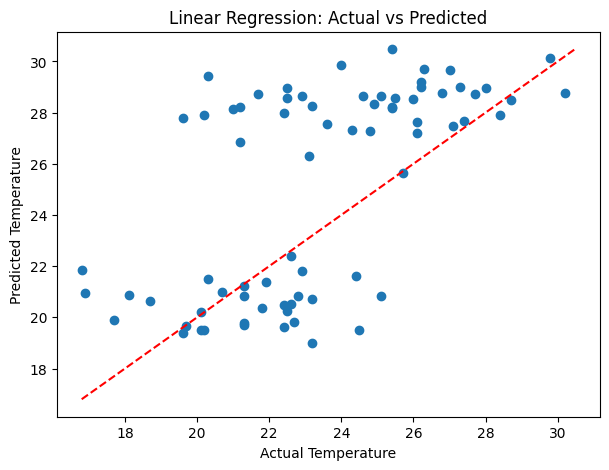

In [ ]:
# Multiple linear regression

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)

def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2 Score": r2_score(actual, predicted)
    }

linear_results = evaluate_model(
    "Multiple Linear Regression",
    y_test,
    linear_predictions
)

display(pd.DataFrame([linear_results]).round(4))

plt.figure(figsize=(7, 5))
plt.scatter(y_test, linear_predictions)
low = min(y_test.min(), linear_predictions.min())
high = max(y_test.max(), linear_predictions.max())
plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual Temperature")
plt.ylabel("Predicted Temperature")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()


In [ ]:
# Ridge and Lasso regression

from sklearn.linear_model import Ridge, Lasso

ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=1.0))
])

lasso_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Lasso(alpha=0.1, max_iter=20000))
])

models = {
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model
}

regularization_results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    regularization_results.append(
        evaluate_model(name, y_test, predictions)
    )

display(pd.DataFrame(regularization_results).round(4))


,Model,MAE,RMSE,R2 Score
0,Ridge Regression,2.8050,3.5778,-0.4157
1,Lasso Regression,2.2176,2.8458,0.1043


In [ ]:
#  Decision Tree and Random Forest

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ))
])

forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        random_state=42,
        n_jobs=-1
    ))
])

tree_model.fit(X_train, y_train)
forest_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)
forest_predictions = forest_model.predict(X_test)

tree_results = evaluate_model(
    "Decision Tree", y_test, tree_predictions
)
forest_results = evaluate_model(
    "Random Forest", y_test, forest_predictions
)

display(pd.DataFrame([
    tree_results, forest_results
]).round(4))


,Model,MAE,RMSE,R2 Score
0,Decision Tree,2.2896,2.9331,0.0485
1,Random Forest,2.5321,3.2074,-0.1377


In [ ]:
#Model selection using time-series cross-validation

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

candidate_models = {
    "Linear Regression": (
        Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", LinearRegression())
        ]),
        {}
    ),

    "Ridge": (
        Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", Ridge())
        ]),
        {"regressor__alpha": [0.1, 1, 10, 100]}
    ),

    "Lasso": (
        Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", Lasso(max_iter=20000))
        ]),
        {"regressor__alpha": [0.01, 0.1, 1.0]}
    ),

    "Decision Tree": (
        Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", DecisionTreeRegressor(random_state=42))
        ]),
        {
            "regressor__max_depth": [3, 5, 8],
            "regressor__min_samples_leaf": [2, 5]
        }
    ),

    "Random Forest": (
        Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", RandomForestRegressor(
                n_estimators=100,
                random_state=42,
                n_jobs=1
            ))
        ]),
        {
            "regressor__max_depth": [4, 8, None],
            "regressor__min_samples_leaf": [2, 5]
        }
    )
}

tscv = TimeSeriesSplit(n_splits=5)
selection_results = []
best_model = None
best_model_name = None
best_cv_rmse = float("inf")

for name, (pipeline, parameters) in candidate_models.items():
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameters,
        scoring="neg_root_mean_squared_error",
        cv=tscv,
        n_jobs=-1
    )

    search.fit(X_train, y_train)

    cv_rmse = -search.best_score_
    predictions = search.predict(X_test)

    selection_results.append({
        "Model": name,
        "CV RMSE": cv_rmse,
        "Test RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "Test MAE": mean_absolute_error(y_test, predictions),
        "Test R2": r2_score(y_test, predictions),
        "Best Parameters": search.best_params_
    })

    if cv_rmse < best_cv_rmse:
        best_cv_rmse = cv_rmse
        best_model = search.best_estimator_
        best_model_name = name

selection_table = pd.DataFrame(
    selection_results
).sort_values("CV RMSE")

display(selection_table.round(4))

print("Selected model:", best_model_name)
print("Best cross-validation RMSE:", round(best_cv_rmse, 4))


,Model,CV RMSE,Test RMSE,Test MAE,Test R2,Best Parameters
1,Ridge,4.6459,3.6219,2.8518,-0.4508,{'regressor__alpha': 0.1}
0,Linear Regression,4.6460,3.6271,2.8576,-0.4550,{}
3,Decision Tree,4.8812,2.9810,2.2569,0.0172,"{'regressor__max_depth': 3, 'regressor__min_sa..."
4,Random Forest,5.0155,3.0665,2.4084,-0.0400,"{'regressor__max_depth': 4, 'regressor__min_sa..."
2,Lasso,5.1402,2.8458,2.2176,0.1043,{'regressor__alpha': 0.1}


Selected model: Ridge
Best cross-validation RMSE: 4.6459


In [ ]:
#Save and load the selected model

import joblib

model_path = "/content/best_temperature_model.joblib"

joblib.dump(best_model, model_path)

print("Model saved successfully:", model_path)

loaded_model = joblib.load(model_path)

# Verify that the saved model produces the same predictions
original_predictions = best_model.predict(X_test)
loaded_predictions = loaded_model.predict(X_test)

print(
    "Saved model verification:",
    np.allclose(original_predictions, loaded_predictions)
)

# Download the model from Colab
from google.colab import files
files.download(model_path)


Model saved successfully: /content/best_temperature_model.joblib
Saved model verification: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

numeric_inputs = {}
categorical_inputs = {}

for col in numeric_features:
    numeric_inputs[col] = widgets.FloatText(
        value=float(X_train[col].median()),
        description=col,
        style={"description_width": "initial"},
        layout=widgets.Layout(width="450px")
    )

for col in categorical_features:
    options = sorted(X_train[col].dropna().unique().tolist())

    categorical_inputs[col] = widgets.Dropdown(
        options=options,
        description=col,
        style={"description_width": "initial"},
        layout=widgets.Layout(width="450px")
    )

predict_button = widgets.Button(
    description="Predict Temperature",
    button_style="primary"
)

output = widgets.Output()

def predict_temperature(button):
    with output:
        clear_output(wait=True)

        values = {}

        for col, widget in numeric_inputs.items():
            values[col] = widget.value

        for col, widget in categorical_inputs.items():
            values[col] = widget.value

        new_data = pd.DataFrame([values], columns=features)
        prediction = loaded_model.predict(new_data)[0]

        print(f"Predicted Temperature: {prediction:.2f}")
        print("Units are the same as the Temperature column in your CSV.")

predict_button.on_click(predict_temperature)

display(widgets.VBox(
    list(numeric_inputs.values())
    + list(categorical_inputs.values())
    + [predict_button, output]
))


In [3]:
!pip install -q streamlit pyngrok scikit-learn pandas


In [5]:
%%writefile app.py
import streamlit as st
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

st.title("E-Commerce Product Price Estimator")
st.write("Enter product details to estimate its price.")

df = pd.read_csv("ecommerce_scraped_data.csv")

features = ["category", "brand", "rating", "variants", "stock", "discount_percent"]

X = df[features]
y = df["price"]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["category", "brand"])
], remainder="passthrough")

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(n_estimators=100, random_state=42))
])

model.fit(X, y)

category = st.selectbox("Category", sorted(df["category"].unique()))
brand = st.selectbox("Brand", sorted(df["brand"].unique()))
rating = st.slider("Rating", 1.0, 5.0, 4.0, 0.1)
variants = st.number_input("Number of Variants", 1, 100, 3)
stock = st.number_input("Stock", 0, 10000, 50)
discount = st.slider("Discount (%)", 0, 100, 10)

if st.button("Estimate Price"):
    data = pd.DataFrame([{
        "category": category,
        "brand": brand,
        "rating": rating,
        "variants": variants,
        "stock": stock,
        "discount_percent": discount
    }])

    price = model.predict(data)[0]
    st.success(f"Estimated Price: ₹{price:.2f}")



Overwriting app.py


In [12]:
from pyngrok import ngrok
import subprocess
import time

# Clean up any existing background ngrok processes
!pkill ngrok
ngrok.kill()

# Configure authtoken
!ngrok config add-authtoken 3LM882gGeW30AKMLAI9BpVoruUc_5pYuN1w9Lxys46xx9Uxfp

# Launch Streamlit on port 8501
process = subprocess.Popen(
    ["streamlit", "run", "app.py", "--server.port", "8501"]
)
time.sleep(5)

try:
    # Try to connect using an explicitly random/ephemeral address
    # By providing no host/domain configurations, we request an ephemeral ngrok URL
    public_url = ngrok.connect(8501, proto="http")
    print("Streamlit App is live at:", public_url)
except Exception as e:
    print("ngrok failed to start due to your static domain assignment. Falling back to Localtunnel...")
    # Install localtunnel
    !npm install -g localtunnel
    # Run localtunnel in background pointing to port 8501
    print("\n--- STARTING LOCALTUNNEL ---")
    print("Click the link below once the URL is generated:")
    subprocess.Popen(["lt", "--port", "8501"])

Authtoken already set in configuration file: /root/.config/ngrok/ngrok.yml


ngrok failed to start due to your static domain assignment. Falling back to Localtunnel...
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧
added 22 packages in 2s
⠧
⠧3 packages are looking for funding
⠧  run `npm fund` for details
⠧
--- STARTING LOCALTUNNEL ---
Click the link below once the URL is generated:


In [ ]:
!npx localtunnel --port 8501


⠙⠹⠸⠼⠴Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) 